# Chapter 7 - Ensemble Construction and Threshold Selection

This notebook combines the tuned A, B and C models from Chapter 6 into four equal-weight soft-voting ensembles: AB, AC, BC and ABC. It compares them on the 4,495 validation rows and selects one threshold for each of A, B, C, AB, AC, BC and ABC.

The test split is not read. No model is refitted. The thresholds are selected on validation only and frozen for Chapter 8.


In [1]:
# 0. Setup: imports, portable paths and fixed seed
from pathlib import Path
import json
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             roc_auc_score, roc_curve)

BASE_DIR = Path("..")
DATA_DIR = BASE_DIR / "data_processed"
PRED_DIR = DATA_DIR / "predictions"
OUT_DIR = BASE_DIR / "outputs" / "chapter_07"
OUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "default.payment.next.month"
ID_COL = "ID"
SEED = 42

if sklearn.__version__ != "1.9.1":
    raise RuntimeError(f"This notebook requires scikit-learn 1.9.1, found {sklearn.__version__}")

np.random.seed(SEED)
pd.set_option("display.width", 140)
print(f"Python {sys.version.split()[0]} | scikit-learn {sklearn.__version__} | "
      f"pandas {pd.__version__} | numpy {np.__version__}")


Python 3.11.9 | scikit-learn 1.9.1 | pandas 3.0.6 | numpy 2.4.6


In [2]:
# 1. Load the frozen Chapter 6 validation probabilities. The test file is not read.
val = pd.read_csv(PRED_DIR / "ch06_tuned_val.csv")

assert len(val) == 4495, len(val)
assert set([ID_COL, TARGET, "p_A", "p_B", "p_C"]).issubset(val.columns)
assert val[[TARGET, "p_A", "p_B", "p_C"]].notna().all().all()
assert val[TARGET].isin([0, 1]).all()

print(f"Validation rows : {len(val):,}")
print(f"Default rate    : {val[TARGET].mean():.4f}")
display(val.head())


Validation rows : 4,495
Default rate    : 0.2211


,ID,default.payment.next.month,p_A,p_B,p_C
0,4576,0,0.412466,0.367570,0.280273
1,9916,0,0.554010,0.544004,0.616391
2,5975,0,0.347789,0.311150,0.357119
3,1122,1,0.903278,0.782921,0.764823
4,16784,1,0.461463,0.349462,0.361850


In [3]:
# 2. Four equal-weight soft-voting ensembles. No model is refitted.
val["p_AB"] = (val["p_A"] + val["p_B"]) / 2
val["p_AC"] = (val["p_A"] + val["p_C"]) / 2
val["p_BC"] = (val["p_B"] + val["p_C"]) / 2
val["p_ABC"] = (val["p_A"] + val["p_B"] + val["p_C"]) / 3

PROB_COLUMNS = {
    "A": "p_A",
    "B": "p_B",
    "C": "p_C",
    "AB": "p_AB",
    "AC": "p_AC",
    "BC": "p_BC",
    "ABC": "p_ABC",
}

for name, column in PROB_COLUMNS.items():
    assert val[column].between(0, 1).all(), name

print("Predictors:", ", ".join(PROB_COLUMNS))
display(val[list(PROB_COLUMNS.values())].describe().round(4))


Predictors: A, B, C, AB, AC, BC, ABC


,p_A,p_B,p_C,p_AB,p_AC,p_BC,p_ABC
count,4495.0000,4495.0000,4495.0000,4495.0000,4495.0000,4495.0000,4495.0000
mean,0.4459,0.4159,0.4138,0.4309,0.4299,0.4149,0.4252
std,0.1902,0.2040,0.2249,0.1897,0.1994,0.2134,0.1991
min,0.0523,0.0901,0.0408,0.0767,0.0548,0.0680,0.0666
25%,0.3170,0.2669,0.2443,0.2911,0.2817,0.2567,0.2779
50%,0.4086,0.3598,0.3608,0.3835,0.3820,0.3585,0.3749
75%,0.5599,0.5165,0.5441,0.5275,0.5425,0.5308,0.5283
max,0.9982,0.9529,0.9552,0.9705,0.9660,0.9541,0.9594


In [4]:
# 3. Threshold-free comparison of the seven predictors.
y_val = val[TARGET].to_numpy()

rows = []
for name, column in PROB_COLUMNS.items():
    proba = val[column].to_numpy()
    rows.append({
        "Model": name,
        "AUC": roc_auc_score(y_val, proba),
        "PR-AUC": average_precision_score(y_val, proba),
    })

table_07_01 = pd.DataFrame(rows)
auc_by_model = table_07_01.set_index("Model")["AUC"]
pr_by_model = table_07_01.set_index("Model")["PR-AUC"]

table_07_01.to_csv(OUT_DIR / "table07_01_threshold_free.csv", index=False)
display(table_07_01.round(4))


,Model,AUC,PR-AUC
0,A,0.7457,0.4966
1,B,0.7777,0.5517
2,C,0.7808,0.5553
3,AB,0.7717,0.5371
4,AC,0.7752,0.5425
5,BC,0.7805,0.5560
6,ABC,0.7781,0.5496


In [5]:
# 4. Threshold grid and a simple metric function.
THRESHOLD_GRID = np.round(np.arange(0.01, 1.00, 0.01), 2)

def metrics_at_threshold(y_true, proba, threshold):
    pred = proba >= threshold
    tp = int(((pred == 1) & (y_true == 1)).sum())
    fp = int(((pred == 1) & (y_true == 0)).sum())
    tn = int(((pred == 0) & (y_true == 0)).sum())
    fn = int(((pred == 0) & (y_true == 1)).sum())

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    accuracy = (tp + tn) / (tp + fp + tn + fn)

    return {
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn,
    }

print(f"Threshold grid: {THRESHOLD_GRID[0]:.2f} to {THRESHOLD_GRID[-1]:.2f}, "
      f"{len(THRESHOLD_GRID)} values")


Threshold grid: 0.01 to 0.99, 99 values


In [6]:
# 5. Select one threshold per predictor: highest validation F1.
selected_rows = []
threshold_curves = {}

for name, column in PROB_COLUMNS.items():
    proba = val[column].to_numpy()
    curve = pd.DataFrame([metrics_at_threshold(y_val, proba, t) for t in THRESHOLD_GRID])
    curve["Distance to 0.5"] = (curve["Threshold"] - 0.5).abs()
    threshold_curves[name] = curve

    f1_at_05 = metrics_at_threshold(y_val, proba, 0.5)["F1"]
    best = curve.sort_values(
        ["F1", "Recall", "Distance to 0.5", "Threshold"],
        ascending=[False, False, True, True],
    ).iloc[0]

    selected_rows.append({
        "Model": name,
        "Threshold": best["Threshold"],
        "Accuracy": best["Accuracy"],
        "Precision": best["Precision"],
        "Recall": best["Recall"],
        "F1": best["F1"],
        "F1 at 0.5": f1_at_05,
    })

table_07_03 = pd.DataFrame(selected_rows)
table_07_03.to_csv(OUT_DIR / "table07_03_selected_thresholds.csv", index=False)
print("Selected thresholds:")
display(table_07_03.round(4))


Selected thresholds:

,Model,Threshold,Accuracy,Precision,Recall,F1,F1 at 0.5
0,A,0.56,0.7726,0.4875,0.5513,0.5175,0.5010
1,B,0.57,0.8038,0.5596,0.5292,0.5440,0.5332
2,C,0.58,0.8018,0.5518,0.5523,0.5520,0.5423
3,AB,0.58,0.8004,0.5505,0.5322,0.5412,0.5304
4,AC,0.60,0.8036,0.5590,0.5292,0.5437,0.5284
5,BC,0.59,0.8085,0.5720,0.5312,0.5509,0.5370
6,ABC,0.57,0.8000,0.5479,0.5463,0.5471,0.5343


In [7]:
# 6. Marginal contribution and the pre-declared final-model rule.
pair_components = {"AB": ("A", "B"), "AC": ("A", "C"), "BC": ("B", "C")}
marginal_rows = []

for candidate, (first, second) in pair_components.items():
    best_component = first if (auc_by_model[first], pr_by_model[first]) >= (
        auc_by_model[second], pr_by_model[second]) else second
    marginal_rows.append({
        "Candidate": candidate,
        "AUC": auc_by_model[candidate],
        "Best component": best_component,
    })

best_pair = max(pair_components, key=lambda name: (auc_by_model[name], pr_by_model[name]))
marginal_rows.append({
    "Candidate": "ABC",
    "AUC": auc_by_model["ABC"],
    "Best component": best_pair,
})

for row in marginal_rows:
    row["Component AUC"] = auc_by_model[row["Best component"]]
    row["Delta AUC"] = row["AUC"] - row["Component AUC"]

table_07_02 = pd.DataFrame(marginal_rows)[
    ["Candidate", "AUC", "Best component", "Component AUC", "Delta AUC"]
]
table_07_02.to_csv(OUT_DIR / "table07_02_marginal.csv", index=False)

ensemble_names = ["AB", "AC", "BC", "ABC"]
best_ensemble = max(ensemble_names, key=lambda name: (auc_by_model[name], pr_by_model[name]))

# The final-model rule was declared before the comparison: keep the selected
# ensemble only when it beats Model C on validation AUC.
final_model = best_ensemble if auc_by_model[best_ensemble] > auc_by_model["C"] else "C"

print(f"Best pairwise ensemble: {best_pair}")
print(f"Selected ensemble     : {best_ensemble}")
print(f"Model C AUC           : {auc_by_model['C']:.4f}")
print(f"Final predictor       : {final_model}")
display(table_07_02.round(4))


Best pairwise ensemble: BC
Selected ensemble     : BC
Model C AUC           : 0.7808
Final predictor       : C


,Candidate,AUC,Best component,Component AUC,Delta AUC
0,AB,0.7717,B,0.7777,-0.0060
1,AC,0.7752,C,0.7808,-0.0057
2,BC,0.7805,C,0.7808,-0.0003
3,ABC,0.7781,BC,0.7805,-0.0024


In [8]:
# 7. Show the threshold-free comparison and the marginal contribution.
display(table_07_01.round(4))
display(table_07_02.round(4))


,Model,AUC,PR-AUC
0,A,0.7457,0.4966
1,B,0.7777,0.5517
2,C,0.7808,0.5553
3,AB,0.7717,0.5371
4,AC,0.7752,0.5425
5,BC,0.7805,0.5560
6,ABC,0.7781,0.5496


,Candidate,AUC,Best component,Component AUC,Delta AUC
0,AB,0.7717,B,0.7777,-0.0060
1,AC,0.7752,C,0.7808,-0.0057
2,BC,0.7805,C,0.7808,-0.0003
3,ABC,0.7781,BC,0.7805,-0.0024


In [9]:
# 8. Show the selected thresholds and their validation metrics.
display(table_07_03.round(4))


,Model,Threshold,Accuracy,Precision,Recall,F1,F1 at 0.5
0,A,0.56,0.7726,0.4875,0.5513,0.5175,0.5010
1,B,0.57,0.8038,0.5596,0.5292,0.5440,0.5332
2,C,0.58,0.8018,0.5518,0.5523,0.5520,0.5423
3,AB,0.58,0.8004,0.5505,0.5322,0.5412,0.5304
4,AC,0.60,0.8036,0.5590,0.5292,0.5437,0.5284
5,BC,0.59,0.8085,0.5720,0.5312,0.5509,0.5370
6,ABC,0.57,0.8000,0.5479,0.5463,0.5471,0.5343


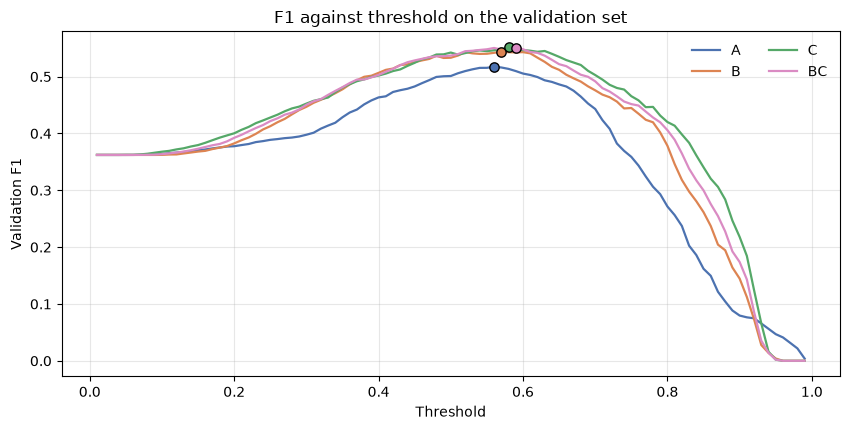

In [10]:
# 9. F1 against threshold for A, B, C and the selected ensemble.
plot_names = ["A", "B", "C", best_ensemble]
colors = {
    "A": "#4C72B0", "B": "#DD8452", "C": "#55A868",
    "AB": "#8172B3", "AC": "#937860", "BC": "#DA8BC3", "ABC": "#8C8C8C",
}

fig, ax = plt.subplots(figsize=(8.6, 4.4))
for name in plot_names:
    curve = threshold_curves[name]
    ax.plot(curve["Threshold"], curve["F1"], linewidth=1.6,
            color=colors[name], label=name)
    best_row = table_07_03[table_07_03["Model"] == name].iloc[0]
    ax.scatter(best_row["Threshold"], best_row["F1"], color=colors[name],
               edgecolor="black", s=45, zorder=4)

ax.set_xlabel("Threshold")
ax.set_ylabel("Validation F1")
ax.set_title("F1 against threshold on the validation set")
ax.grid(alpha=0.3)
ax.legend(frameon=False, ncol=2)
fig.tight_layout()
fig.savefig(OUT_DIR / "fig_7_f1_threshold.png", dpi=300)
plt.show()


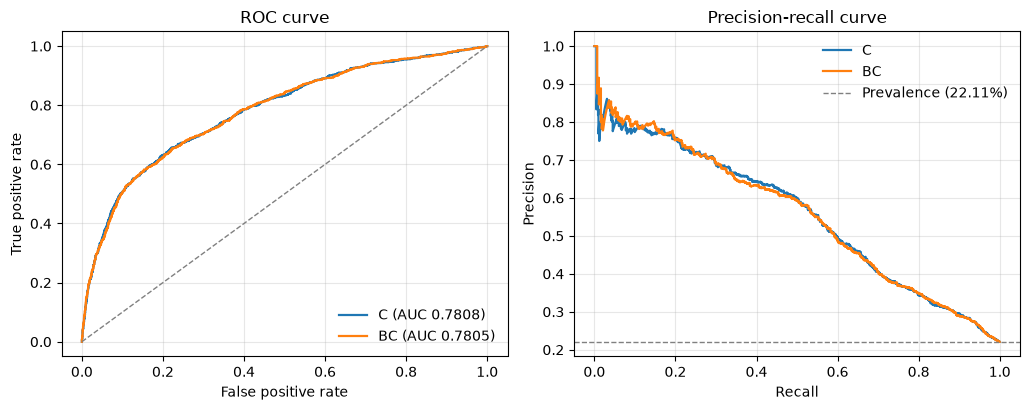

In [11]:
# 10. ROC and precision-recall curves for C and the selected ensemble.
fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.2))
prevalence = val[TARGET].mean()

for name in ["C", best_ensemble]:
    proba = val[PROB_COLUMNS[name]].to_numpy()
    fpr, tpr, _ = roc_curve(y_val, proba)
    precision, recall, _ = precision_recall_curve(y_val, proba)
    auc = auc_by_model[name]
    axes[0].plot(fpr, tpr, linewidth=1.6, label=f"{name} (AUC {auc:.4f})")
    axes[1].plot(recall, precision, linewidth=1.6, label=name)

axes[0].plot([0, 1], [0, 1], linestyle="--", color="grey", linewidth=1)
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curve")
axes[0].legend(frameon=False, loc="lower right")

axes[1].axhline(prevalence, linestyle="--", color="grey", linewidth=1,
                label=f"Prevalence ({prevalence:.2%})")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curve")
axes[1].legend(frameon=False, loc="upper right")

for ax in axes:
    ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(OUT_DIR / "fig_7_roc_pr.png", dpi=300)
plt.show()


In [12]:
# 11. Save the ensemble validation probabilities for Chapter 8.
output = val[[ID_COL, TARGET, "p_A", "p_B", "p_C",
              "p_AB", "p_AC", "p_BC", "p_ABC"]].copy()
output.to_csv(PRED_DIR / "ch07_ensemble_val.csv", index=False)
print("Saved", PRED_DIR / "ch07_ensemble_val.csv")


Saved ..\data_processed\predictions\ch07_ensemble_val.csv


In [13]:
# 12. Save the run manifest.
manifest = {
    "chapter": "07_ensemble_threshold",
    "random_seed": SEED,
    "data": {
        "validation_rows": int(len(val)),
        "test_split_used": False,
    },
    "protocol": {
        "ensemble": "equal-weight soft voting",
        "threshold_grid": [float(THRESHOLD_GRID[0]), float(THRESHOLD_GRID[-1]),
                           float(THRESHOLD_GRID[1] - THRESHOLD_GRID[0])],
        "threshold_metric": "validation_f1",
        "tie_breakers": ["recall", "distance_to_0.5", "threshold"],
        "ensemble_selection": "validation_auc_then_pr_auc",
        "final_model_rule": "selected_ensemble_if_auc_above_C_else_C",
    },
    "selected_ensemble": best_ensemble,
    "final_model": final_model,
    "thresholds": {
        row["Model"]: float(row["Threshold"])
        for _, row in table_07_03.iterrows()
    },
    "environment": {
        "python": sys.version.split()[0],
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__,
        "matplotlib": matplotlib.__version__,
    },
    "artifacts": {
        "table_07_01": "bank/outputs/chapter_07/table07_01_threshold_free.csv",
        "table_07_02": "bank/outputs/chapter_07/table07_02_marginal.csv",
        "table_07_03": "bank/outputs/chapter_07/table07_03_selected_thresholds.csv",
        "figure_07_05": "bank/outputs/chapter_07/fig_7_f1_threshold.png",
        "figure_07_07": "bank/outputs/chapter_07/fig_7_roc_pr.png",
        "ensemble_validation_probabilities": "bank/data_processed/predictions/ch07_ensemble_val.csv",
    },
}
(OUT_DIR / "run_manifest.json").write_text(
    json.dumps(manifest, indent=2), encoding="utf-8")
print("Saved", OUT_DIR / "run_manifest.json")


Saved ..\outputs\chapter_07\run_manifest.json


## Summary

The notebook has compared A, B, C, AB, AC, BC and ABC on the validation split, selected BC as the best ensemble by validation AUC, and frozen one threshold per predictor.

Model C still has the highest single-model AUC, so the pre-declared rule keeps Model C as the final predictor. BC remains the selected ensemble for the Chapter 8 comparison.

`test.csv` has not been read. Chapter 8 applies the frozen thresholds once.
